# Teste de Hipótese 

### Monstro: Beholder

Autor: **Carlos Gabriel de Oliveira Campos**

Professor Dr. **Daniel Roberto Cassar**

Introdução

___


## Contextualização

A confirmação da teoria da Relatividade Geral de Albert Einstein durante o eclipse 
solar de 1919 é um momento marcante na história da ciência. O experimento, conduzido 
por Sir Arthur Eddington, tinha como objetivo testar uma das principais previsões da 
Relatividade Geral: a curvatura da luz pela gravidade.
A Teoria Geral da Relatividade de Einstein, publicada em 1915, introduziu uma 
nova compreensão da gravidade. Em vez da visão clássica da gravidade como uma força, 
a teoria de Einstein propôs que objetos massivos, como o Sol, deformam o tecido do 
espaço‑tempo ao seu redor. A luz que passa perto de um objeto massivo destes seguiria 
um caminho curvo devido a essa distorção, criando o efeito de lente gravitacional.
A teoria de Einstein previu que, durante um eclipse solar, quando a massa do Sol 
bloqueasse a luz de estrelas distantes, as posições dessas estrelas pareceriam deslocadas 
devido ao campo gravitacional do Sol. As posições observadas das estrelas seriam 
diferentes de suas posições esperadas se a gravidade não afetasse a luz. Especificamente, 
as posições das estrelas seriam deslocadas para fora do Sol.
Os resultados esperados do experimento envolviam a medição do deslocamento 
angular das estrelas quando elas apareciam perto do Sol durante um eclipse solar total. 
O deslocamento angular seria a diferença entre a posição aparente de uma estrela e sua 
posição real na ausência da gravidade do Sol.
A teoria de Einstein previu que esse deslocamento angular seria de aproximadamente 
1.75 segundo de arco (arcseg) para estrelas que estivessem próximas ao Sol durante 
o eclipse.
Arthur Eddington organizou duas expedições (uma para Sobral, no Brasil, e outra 
para a Ilha do Príncipe, na África Ocidental) para observar o eclipse solar total de 29 
de maio de 1919. As equipes tiraram fotografias das estrelas que estavam próximas ao 
Sol durante o eclipse.
As fotografias tiradas durante o eclipse foram comparadas com fotografias do mesmo 
campo estelar tiradas quando o Sol não estava nas proximidades. As posições observadas 
das estrelas foram de fato deslocadas para fora do Sol, de acordo com as previsões de 
Einstein.

## Exercício

> Suponha que pelo modelo de Einstein e pelos equipamentos utilizados, o valor esperado para o deslocamento angular segue uma distribuição normal 𝒩︀(1.75,0.02) (isto é, tem média de 1.75 e variância de 0.02). Proponha e execute um teste de hipótese para testar o modelo de Einstein à luz do resultado obtido, usando de simulação, sabendo que **o deslocamento angular medido das estrelas durante o eclipse de 1919 
foi de aproximadamente 1.98 arcseg**.

Para este problema, podemos formular nossa **hipótese nula** $H_0$ de forma que o deslocamento angular segue a distribuição informada. Ademais, será adotado um valor de 5% para a significância, uma vez que este é o padrão geral na ciência, e não há condições especiais particulares a essa questão para mudá-lo [1].  

In [80]:
SIGNIFICANCIA = 0.05

Faremos os seguintes imports para o notebook

In [21]:
import numpy as np
import scipy.stats as stats
import seaborn as sns

Montando a distribuição informada

In [51]:
# Gera distribuicao
VAL_CALC = 1.75
DESV_PADRAO = 0.02 ** (1/2)
dist = stats.norm(loc=VAL_CALC, scale=DESV_PADRAO)

Plotando e visualizando a distribuição

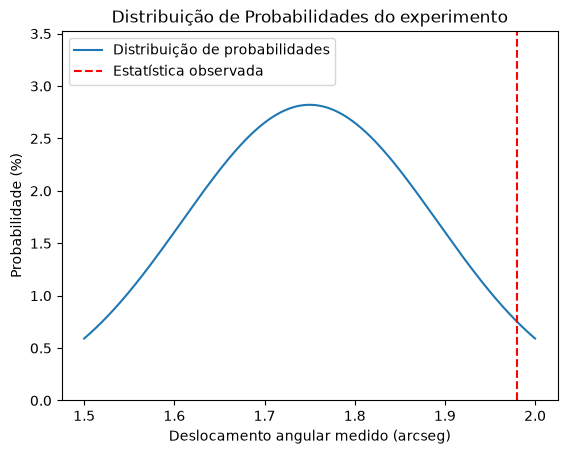

In [52]:

# Plota distribuicao
x = np.linspace(1.5, 2, num=300)
y = dist.pdf(x)
eixo = sns.lineplot(x=x, y=y, label="Distribuição de probabilidades")

# Configurações do gráfico
eixo.set(
    xticks=np.linspace(1.5, 2, 6),
    title="Distribuição de Probabilidades do experimento",
    ylabel="Probabilidade (%)",
    xlabel="Deslocamento angular medido (arcseg)"
    );


# Plota linha do valor medido
VAL_MEDIDO = 1.98
eixo.axvline(
    VAL_MEDIDO,
    label="Estatística observada",
    color="red",
    linestyle="--"
)

eixo.set_ylim(bottom=0, top=max(y) * 1.25) # para evitar sobreposição de elementos
eixo.legend();

Nesse caso, o valor medido para o deslocamento angular foi de 0.23 arcseg maior do que a média, de acordo com $H_0$. Como a dsitribuição possui um eixo de simetria ao redor da média, podemos afirmar que essa medida está tão "distante" de $H_0$ como uma medida 0.23 arcseg *abaixo da média* (1.52 arcseg). Dessa maneira, o material em [2] nos auxiliar a compreender o cálculo do p-valor

## Realizando a simulação

In [61]:
# Configurando semente aleatória
np.random.seed(42)

# Realizando 1 milhão de simulações
num_simulacoes = 1_000_000
x = np.random.normal(loc=VAL_CALC, scale=DESV_PADRAO, size=num_simulacoes)

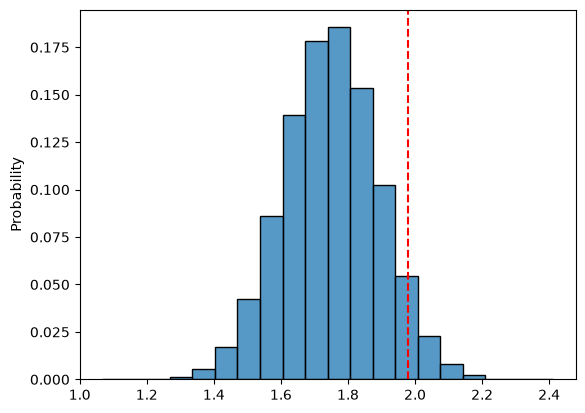

In [66]:
eixo = sns.histplot(
    x,
    stat="probability",
    bins=20,
    label="Distribuição de probabilidades",
)

eixo.axvline(
    VAL_MEDIDO,
    label="Estatística observada",
    color="red",
    linestyle="--"
)

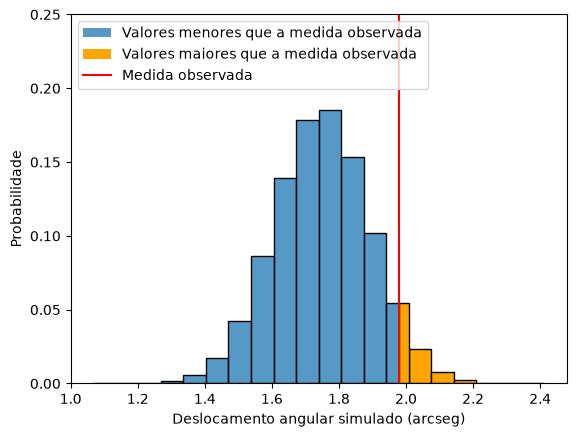

In [79]:
histograma_pvalor(x, VAL_MEDIDO)

$$
\textrm{p-valor} = P(X \leq 1.52 | H_0) + P(X \geq 1.98 | H_0).
$$

Devido à simetria

$$
P(X \leq 1.52 | H_0) = P(X \geq 1.98 | H_0)
$$

Logo, podemos simplificar para

$$
\textrm{p-valor} = 2 \cdot P(X \geq 1.98 | H_0).
$$

Se $H_0$ é verdadeira, então a variável $X$ deve serguir a **distribuição normal** com média em 1.75 e variância de 0.02:

$$
\textrm{p-valor} = 2 \cdot P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)).
$$

Uma forma de calcular estas probabilidades é pela cdf da distribuição Normal:

$$
P(X \geq 1.98 | X \sim \mathrm{Normal}(1.75,0.02)) = 1 - F(1.98| 1.75, 0.02)
$$


Vamos calcular computacionalmente o p-valor:

In [53]:
p_valor = 2 * (1 - dist.cdf(VAL_MEDIDO))

print(f"p-valor calculado: {p_valor}")

p-valor calculado: 0.10387615706308506


Pode parecer estranho que o resultado seja 0, mas ocorre que o valor da cauda a partir desse ponto é tão diminuto, que a resolução dos dígitos não é suficiente para diferenciar o valor calculado de 0. Entretanto, podemos contornar esse problema ao aplocar o método `.sf` (Survival Function), que calculada a área distribuição *a partir* de determinado ponto, com maior resolução. 

In [54]:
p_valor = 2 * (dist.sf(1.98))

print(f"p-valor calculado: {p_valor}")

p-valor calculado: 0.103876157063085


## Conclusão

(TODO)

## Referências

[1] https://scienceinsights.org/what-percentage-is-statistically-significant-5-and-beyond/#:~:text=The%20standard%20threshold%20for%20statistical%20significance%20is%205%25%2C,is%20the%20most%20widely%20used%20convention%20in%20research.

[2] CASSAR, Daniel R. Material de aula **LMA-203 8.0 - Introdução aos testes de hipótese** para a disciplina de Estatística, 2026.


## Uso de IA neste trabalho

(todo)

## Função de suporte 

In [78]:
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import seaborn as sns


def histograma_pvalor(resultado, estatistica_observada):
    eixo = sns.histplot(
        resultado,
        stat="probability",
        bins=20,
    )

    cor_normal = eixo.patches[0].get_facecolor()
    cor_destaque = "orange"

    for barra in list(eixo.patches):
        x_esq = barra.get_x()
        x_dir = x_esq + barra.get_width()
        altura = barra.get_height()

        if x_dir <= estatistica_observada:
            pass

        elif x_esq >= estatistica_observada:
            barra.set_facecolor(cor_destaque)

        else:
            barra.set_width(estatistica_observada - x_esq)

            retangulo_laranja = plt.Rectangle(
                (estatistica_observada, 0),
                x_dir - estatistica_observada,
                altura,
                facecolor=cor_destaque,
                edgecolor=barra.get_edgecolor(),
                linewidth=barra.get_linewidth(),
            )
            eixo.add_patch(retangulo_laranja)

    eixo.axvline(estatistica_observada, color="red", linestyle="-")

    legendas = [
        mpatches.Patch(
            facecolor=cor_normal,
            label="Valores menores que a medida observada",
        ),
        mpatches.Patch(
            facecolor=cor_destaque,
            label="Valores maiores que a medida observada",
        ),
        mlines.Line2D(
            [], [], color="red", linestyle="-", label="Medida observada"
        ),
    ]

    # Altura baseada nas barras reais geradas
    altura_maxima = max(barra.get_height() for barra in eixo.patches)
    eixo.set_ylim(bottom=0, top=altura_maxima * 1.35)

    eixo.set(
        xlabel="Deslocamento angular simulado (arcseg)",
        ylabel="Probabilidade"
    )
    # loc="upper left" posiciona a legenda longe da linha em x = 1.98
    eixo.legend(handles=legendas, loc="upper left")